In [2]:
print("AnomalyDetection")

AnomalyDetection


In [3]:
import pandas as pd

In [4]:
import pandas as pd

In [5]:
df = pd.read_parquet("../data/Benign-Monday-no-metadata.parquet")

In [6]:
df.head()

,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,6,4,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
1,6,1,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
2,6,3,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
3,6,1,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
4,6,609,7,4,484,414,233,0,69.14286,111.967896,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign


In [7]:
df.shape

(458831, 78)

In [8]:
df.columns

Index(['Protocol', 'Flow Duration', 'Total Fwd Packets',
       'Total Backward Packets', 'Fwd Packets Length Total',
       'Bwd Packets Length Total', 'Fwd Packet Length Max',
       'Fwd Packet Length Min', 'Fwd Packet Length Mean',
       'Fwd Packet Length Std', 'Bwd Packet Length Max',
       'Bwd Packet Length Min', 'Bwd Packet Length Mean',
       'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s',
       'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min',
       'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max',
       'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std',
       'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags',
       'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length',
       'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s',
       'Packet Length Min', 'Packet Length Max', 'Packet Length Mean',
       'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count',
       'SYN Flag Count', 'RST Fla

In [9]:
df['Label'].value_counts()

Label
Benign    458831
Name: count, dtype: int64

In [10]:
df_bruteforce = pd.read_parquet(
    "../data/Bruteforce-Tuesday-no-metadata.parquet"
)

In [11]:
df_bruteforce['Label'].value_counts()

Label
Benign         380564
FTP-Patator      5931
SSH-Patator      3219
Name: count, dtype: int64

In [12]:
df_bruteforce.shape

(389714, 78)

In [13]:
df_bruteforce.isnull().sum().sum()

np.int64(0)

In [14]:
import numpy as np

In [15]:
np.isinf(df_bruteforce.select_dtypes(include='number')).sum().sum()

np.int64(0)

In [16]:
import numpy as np

In [17]:
np.isinf(df_bruteforce.select_dtypes(include='number')).sum().sum()

np.int64(0)

In [18]:
df_bruteforce.duplicated().sum()

np.int64(0)

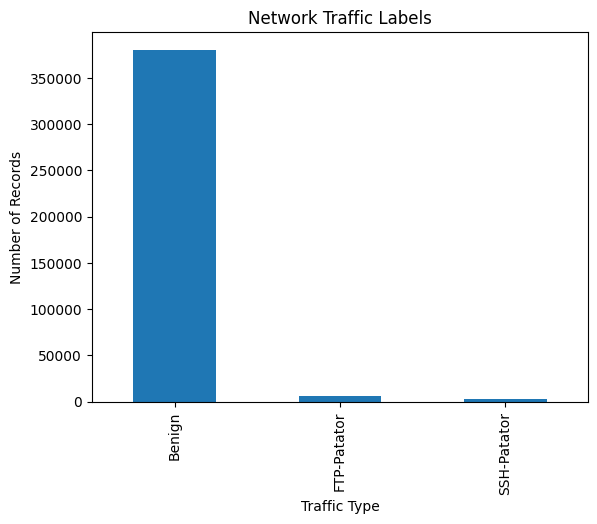

In [19]:
import matplotlib.pyplot as plt

df_bruteforce['Label'].value_counts().plot(kind='bar')

plt.title("Network Traffic Labels")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Records")
plt.show()

In [20]:
df_bruteforce.groupby('Label')['Flow Duration'].mean()

C:\Users\ACER\AppData\Local\Temp\ipykernel_4420\2198502098.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_bruteforce.groupby('Label')['Flow Duration'].mean()


Label
Benign         1.243427e+07
FTP-Patator    6.040451e+06
SSH-Patator    1.130109e+07
Name: Flow Duration, dtype: float64

C:\Users\ACER\AppData\Local\Temp\ipykernel_4420\1292602581.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_bruteforce.groupby('Label')['Flow Duration'].mean().plot(kind='bar')


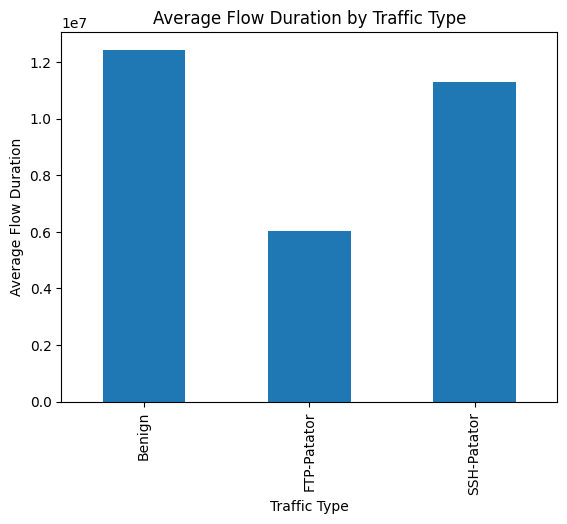

In [21]:
df_bruteforce.groupby('Label')['Flow Duration'].mean().plot(kind='bar')

plt.title("Average Flow Duration by Traffic Type")
plt.xlabel("Traffic Type")
plt.ylabel("Average Flow Duration")
plt.show()

In [22]:
df_bruteforce.groupby('Label')['Flow Packets/s'].mean()

C:\Users\ACER\AppData\Local\Temp\ipykernel_4420\1853094147.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_bruteforce.groupby('Label')['Flow Packets/s'].mean()


Label
Benign         22706.591390
FTP-Patator     7281.311358
SSH-Patator     3123.531030
Name: Flow Packets/s, dtype: float64

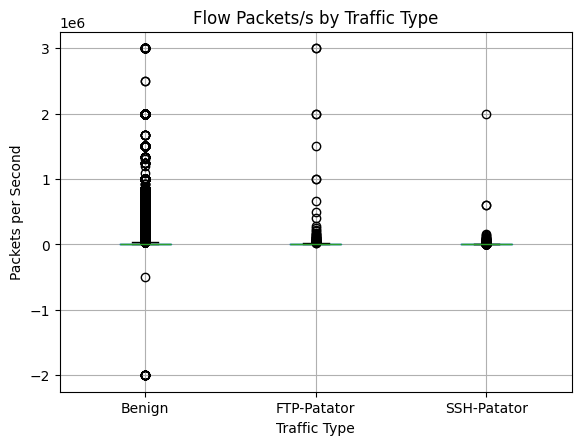

In [23]:
df_bruteforce.boxplot(column='Flow Packets/s', by='Label')

plt.title("Flow Packets/s by Traffic Type")
plt.suptitle("")
plt.xlabel("Traffic Type")
plt.ylabel("Packets per Second")
plt.show()

In [24]:
df_bruteforce['Label'].unique()

['Benign', 'FTP-Patator', 'SSH-Patator']
Categories (3, object): ['Benign', 'FTP-Patator', 'SSH-Patator']

In [25]:
df_bruteforce['Target'] = df_bruteforce['Label'].apply(
    lambda x: 0 if x == 'Benign' else 1
)

In [26]:
df_bruteforce['Target'].value_counts()

Target
0    380564
1      9150
Name: count, dtype: int64

In [27]:
X = df_bruteforce.drop(columns=['Label', 'Target'])

In [28]:
y = df_bruteforce['Target']

In [29]:
X.shape

(389714, 77)

In [30]:
y.shape

(389714,)

In [31]:
from sklearn.model_selection import train_test_split

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [33]:
from sklearn.model_selection import train_test_split


In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [35]:
X_train.shape
X_test.shape
y_train.value_counts()
y_test.value_counts()

Target
0    76113
1     1830
Name: count, dtype: int64

In [36]:
y_train.value_counts()

Target
0    304451
1      7320
Name: count, dtype: int64

In [37]:
from sklearn.preprocessing import StandardScaler

In [38]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Standard scaling helps to make all the values/ feature in same scale 

In [39]:
scaler = StandardScaler()

In [40]:
from sklearn.linear_model import LogisticRegression

In [41]:
model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

In [42]:
model.fit(X_train_scaled, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [43]:
y_pred = model.predict(X_test_scaled)

In [44]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      1.00     76113
           1       0.73      0.97      0.83      1830

    accuracy                           0.99     77943
   macro avg       0.86      0.98      0.91     77943
weighted avg       0.99      0.99      0.99     77943



In [45]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[75449   664]
 [   62  1768]]


In [46]:
from sklearn.ensemble import RandomForestClassifier

In [47]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

In [48]:
rf_model.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [49]:
rf_pred = rf_model.predict(X_test)

In [50]:
print(X.shape)
print(y.value_counts())

(389714, 77)
Target
0    380564
1      9150
Name: count, dtype: int64


In [51]:
from sklearn.metrics import classification_report

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     76113
           1       1.00      1.00      1.00      1830

    accuracy                           1.00     77943
   macro avg       1.00      1.00      1.00     77943
weighted avg       1.00      1.00      1.00     77943



In [52]:
from sklearn.metrics import confusion_matrix

rf_cm = confusion_matrix(y_test, rf_pred)
print(rf_cm)

[[76109     4]
 [    3  1827]]


Creating Confusion Matrix

In [53]:
import pandas as pd

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(feature_importance.head(10))

Fwd Packet Length Std     0.079978
Init Bwd Win Bytes        0.070793
Subflow Bwd Packets       0.040970
Bwd Packet Length Mean    0.039736
Flow IAT Max              0.037278
Bwd IAT Std               0.035969
Fwd Act Data Packets      0.034112
Bwd Header Length         0.033786
Avg Bwd Segment Size      0.030533
Fwd PSH Flags             0.028542
dtype: float64


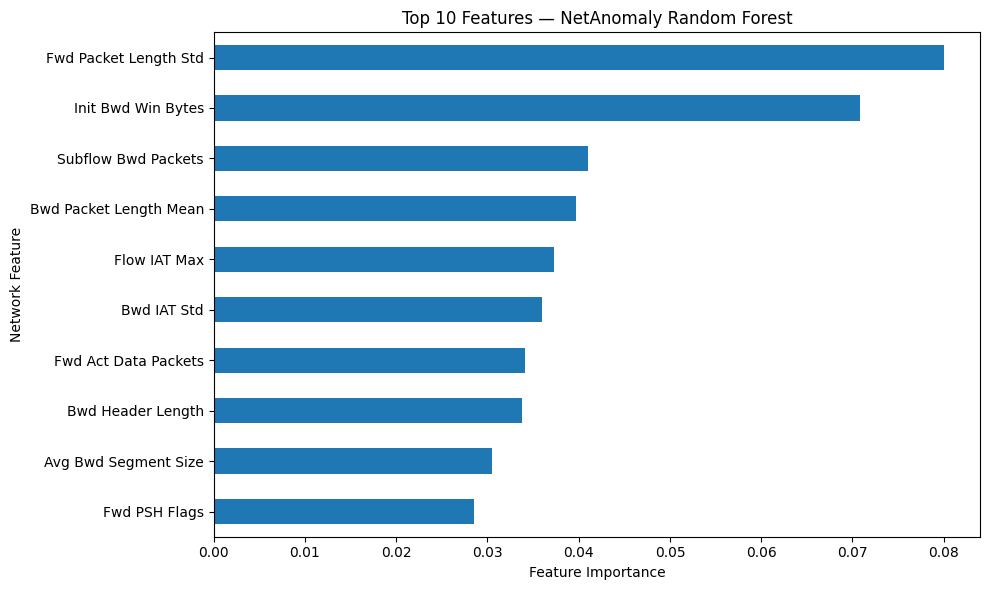

In [54]:
import matplotlib.pyplot as plt

top_10 = feature_importance.head(10).sort_values()

plt.figure(figsize=(10, 6))
top_10.plot(kind='barh')
plt.xlabel("Feature Importance")
plt.ylabel("Network Feature")
plt.title("Top 10 Features — NetAnomaly Random Forest")
plt.tight_layout()
plt.show()

A plot makes it easier to compare features and explain your model in a demo

In [55]:
train_index = set(X_train.index)
test_index = set(X_test.index)

print("Overlapping rows:", len(train_index & test_index))

Overlapping rows: 0


In [56]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, rf_pred))

[[76109     4]
 [    3  1827]]


In [57]:
print("Duplicate feature rows:", X.duplicated().sum())

Duplicate feature rows: 0


In [58]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Attack Precision:", precision_score(y_test, rf_pred))
print("Attack Recall:", recall_score(y_test, rf_pred))
print("Attack F1-score:", f1_score(y_test, rf_pred))

Accuracy: 0.9999101907804421
Attack Precision: 0.997815401419989
Attack Recall: 0.9983606557377049
Attack F1-score: 0.9980879541108987


In [59]:
print(df_bruteforce["Label"].value_counts())

Label
Benign         380564
FTP-Patator      5931
SSH-Patator      3219
Name: count, dtype: int64


In [60]:
print("Number of features:", X.shape[1])
print("First 10 features:")
print(X.columns[:10].tolist())

Number of features: 77
First 10 features:
['Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Fwd Packets Length Total', 'Bwd Packets Length Total', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std']


In [61]:
print("Label in X:", "Label" in X.columns)
print("Target in X:", "Target" in X.columns)
print("Total columns in original data:", df_bruteforce.shape[1])

Label in X: False
Target in X: False
Total columns in original data: 79


In [62]:
print(X.dtypes.value_counts())

int32      25
float32    22
int8       20
int16       7
float64     2
int64       1
Name: count, dtype: int64


In [63]:
import numpy as np

print("Infinite values:", np.isinf(X.select_dtypes(include="number")).sum().sum())
print("Missing values:", X.isna().sum().sum())

Infinite values: 0
Missing values: 0


In [64]:
df_dos = pd.read_parquet(
    "../data/DoS-Wednesday-no-metadata.parquet"
)

print("Dataset shape:", df_dos.shape)
print(df_dos["Label"].value_counts())

Dataset shape: (584991, 78)
Label
Benign              391235
DoS Hulk            172846
DoS GoldenEye        10286
DoS slowloris         5385
DoS Slowhttptest      5228
Heartbleed              11
Name: count, dtype: int64


In [65]:
print("Training feature count:", len(X.columns))
print("Wednesday columns excluding Label:", len(df_dos.columns) - 1)

print("Columns missing from Wednesday:")
print(sorted(set(X.columns) - set(df_dos.columns)))

print("Extra columns in Wednesday:")
print(sorted(set(df_dos.columns) - set(X.columns) - {"Label"}))

Training feature count: 77
Wednesday columns excluding Label: 77
Columns missing from Wednesday:
[]
Extra columns in Wednesday:
[]


In [66]:
df_dos["Target"] = (df_dos["Label"] != "Benign").astype(int)

print(df_dos["Target"].value_counts())

Target
0    391235
1    193756
Name: count, dtype: int64


In [67]:
X_dos = df_dos[X.columns]

y_dos = df_dos["Target"]

print("Test features shape:", X_dos.shape)
print("Test labels shape:", y_dos.shape)

Test features shape: (584991, 77)
Test labels shape: (584991,)


In [68]:
from sklearn.metrics import classification_report, confusion_matrix

dos_pred = rf_model.predict(X_dos)

print("Confusion Matrix:")
print(confusion_matrix(y_dos, dos_pred))

print("\nClassification Report:")
print(classification_report(y_dos, dos_pred))

Confusion Matrix:
[[391209     26]
 [193756      0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.67      1.00      0.80    391235
           1       0.00      0.00      0.00    193756

    accuracy                           0.67    584991
   macro avg       0.33      0.50      0.40    584991
weighted avg       0.45      0.67      0.54    584991



In [69]:
print("Wednesday predictions:")
print(pd.Series(dos_pred).value_counts())

Wednesday predictions:
0    584965
1        26
Name: count, dtype: int64


In [71]:
results = pd.DataFrame({
    "Actual_Label": df_dos["Label"],
    "Actual_Target": y_dos,
    "Predicted": dos_pred
})

print(
    results.groupby("Actual_Label", observed=False)["Predicted"]
    .value_counts()
    .unstack(fill_value=0)
)

Predicted              0   1
Actual_Label                
Benign            391209  26
DoS GoldenEye      10286   0
DoS Hulk          172846   0
DoS Slowhttptest    5228   0
DoS slowloris       5385   0
Heartbleed            11   0


In [72]:
print("Tuesday shape:", df_bruteforce.shape)
print("Wednesday shape:", df_dos.shape)

print(
    "Feature columns match:",
    list(X.columns) == list(X_dos.columns)
)

print("Tuesday target counts:")
print(df_bruteforce["Target"].value_counts())

print("Wednesday target counts:")
print(df_dos["Target"].value_counts())

Tuesday shape: (389714, 79)
Wednesday shape: (584991, 79)
Feature columns match: True
Tuesday target counts:
Target
0    380564
1      9150
Name: count, dtype: int64
Wednesday target counts:
Target
0    391235
1    193756
Name: count, dtype: int64


In [73]:
df_combined = pd.concat(
    [df_bruteforce, df_dos],
    ignore_index=True
)

print("Combined shape:", df_combined.shape)
print("\nAttack/normal counts:")
print(df_combined["Target"].value_counts())

print("\nOriginal attack types:")
print(df_combined["Label"].value_counts())

Combined shape: (974705, 79)

Attack/normal counts:
Target
0    771799
1    202906
Name: count, dtype: int64

Original attack types:
Label
Benign              771799
DoS Hulk            172846
DoS GoldenEye        10286
FTP-Patator           5931
DoS slowloris         5385
DoS Slowhttptest      5228
SSH-Patator           3219
Heartbleed              11
Name: count, dtype: int64


In [74]:
X_combined = df_combined.drop(columns=["Label", "Target"])
y_combined = df_combined["Target"]

print("Features shape:", X_combined.shape)
print("Target shape:", y_combined.shape)

Features shape: (974705, 77)
Target shape: (974705,)


In [75]:
from sklearn.model_selection import train_test_split

X_train_combined, X_test_combined, y_train_combined, y_test_combined = train_test_split(
    X_combined,
    y_combined,
    test_size=0.2,
    stratify=y_combined,
    random_state=42
)

print("Training shape:", X_train_combined.shape)
print("Testing shape:", X_test_combined.shape)

print("\nTraining class counts:")
print(y_train_combined.value_counts())

print("\nTesting class counts:")
print(y_test_combined.value_counts())

Training shape: (779764, 77)
Testing shape: (194941, 77)

Training class counts:
Target
0    617439
1    162325
Name: count, dtype: int64

Testing class counts:
Target
0    154360
1     40581
Name: count, dtype: int64


In [76]:
from sklearn.ensemble import RandomForestClassifier

rf_combined = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_combined.fit(X_train_combined, y_train_combined)

print("Combined-data model training complete!")

Combined-data model training complete!


In [77]:
from sklearn.metrics import classification_report, confusion_matrix

combined_pred = rf_combined.predict(X_test_combined)

print("Confusion Matrix:")
print(confusion_matrix(y_test_combined, combined_pred))

print("\nClassification Report:")
print(classification_report(y_test_combined, combined_pred))

Confusion Matrix:
[[154231    129]
 [    60  40521]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    154360
           1       1.00      1.00      1.00     40581

    accuracy                           1.00    194941
   macro avg       1.00      1.00      1.00    194941
weighted avg       1.00      1.00      1.00    194941



In [78]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test_combined, combined_pred))
print("Attack Precision:", precision_score(y_test_combined, combined_pred))
print("Attack Recall:", recall_score(y_test_combined, combined_pred))
print("Attack F1-score:", f1_score(y_test_combined, combined_pred))

Accuracy: 0.9990304758875762
Attack Precision: 0.9968265682656826
Attack Recall: 0.9985214755673838
Attack F1-score: 0.9976733020644828


In [79]:
df_ddos = pd.read_parquet("../data/DDoS-Friday-no-metadata.parquet")

print("Dataset shape:", df_ddos.shape)
print("\nLabel counts:")
print(df_ddos["Label"].value_counts())

Dataset shape: (221264, 78)

Label counts:
Label
DDoS      128014
Benign     93250
Name: count, dtype: int64


In [80]:
# Check whether Friday has the same features as our training data
ddos_features = df_ddos.drop(columns=["Label"])

print("Training feature count:", X_combined.shape[1])
print("Friday feature count:", ddos_features.shape[1])

print("Missing features:", set(X_combined.columns) - set(ddos_features.columns))
print("Extra features:", set(ddos_features.columns) - set(X_combined.columns))

Training feature count: 77
Friday feature count: 77
Missing features: set()
Extra features: set()


In [81]:
# 0 = Benign traffic, 1 = Attack traffic
y_ddos = (df_ddos["Label"] != "Benign").astype(int)

# Keep the exact feature order used during training
X_ddos = df_ddos[X_combined.columns]

print("Feature shape:", X_ddos.shape)
print("\nActual class counts:")
print(y_ddos.value_counts())


Feature shape: (221264, 77)

Actual class counts:
Label
1    128014
0     93250
Name: count, dtype: int64


In [82]:
# Predict using the model trained on Tuesday + Wednesday
ddos_pred = rf_combined.predict(X_ddos)

print("Predictions completed!")
print("Total predictions:", len(ddos_pred))

Predictions completed!
Total predictions: 221264


In [83]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
print(confusion_matrix(y_ddos, ddos_pred))

print("\nClassification Report:")
print(classification_report(
    y_ddos,
    ddos_pred,
    target_names=["Benign", "Attack"]
))

Confusion Matrix:
[[ 93204     46]
 [105740  22274]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.47      1.00      0.64     93250
      Attack       1.00      0.17      0.30    128014

    accuracy                           0.52    221264
   macro avg       0.73      0.59      0.47    221264
weighted avg       0.77      0.52      0.44    221264



In [84]:
# Compare Friday's feature ranges with the training data
train_min = X_train_combined.min()
train_max = X_train_combined.max()

outside_range = (
    (X_ddos < train_min) | (X_ddos > train_max)
)

print(
    "Features with values outside training ranges:",
    outside_range.any(axis=0).sum(),
    "out of",
    X_ddos.shape[1]
)

print("\nTop 10 features by percentage of Friday records outside training ranges:")
print(
    (outside_range.mean() * 100)
    .sort_values(ascending=False)
    .head(10)
    .round(2)
    .astype(str) + "%"
)

Features with values outside training ranges: 7 out of 77

Top 10 features by percentage of Friday records outside training ranges:
Packet Length Variance      0.12%
Packet Length Std           0.12%
Fwd Packet Length Std        0.0%
Bwd Packet Length Mean       0.0%
Bwd Packet Length Std        0.0%
Fwd IAT Min                  0.0%
Avg Bwd Segment Size         0.0%
Bwd Packets Length Total     0.0%
Total Backward Packets       0.0%
Fwd Packets Length Total     0.0%
dtype: object


In [85]:
import pandas as pd

feature = "Fwd Packet Length Std"

print("Training data:")
print(
    df_combined.groupby("Label", observed=True)[feature]
    .agg(["mean", "median", "std"])
    .round(2)
)

print("\nFriday data:")
print(
    df_ddos.groupby("Label", observed=True)[feature]
    .agg(["mean", "median", "std"])
    .round(2)
)

Training data:
                        mean      median         std
Label                                               
Benign             69.529999    0.000000  234.580002
DoS GoldenEye     128.610001  142.479996   87.669998
DoS Hulk          128.419998  134.559998   50.400002
DoS Slowhttptest   58.889999    0.000000   99.879997
DoS slowloris      44.439999    0.000000   52.540001
FTP-Patator         9.640000    9.900000    0.900000
Heartbleed        100.269997  110.120003   57.380001
SSH-Patator       129.039993  140.050003   38.590000

Friday data:
              mean  median          std
Label                                  
Benign  511.690002    0.00  1178.390015
DDoS      5.720000    5.66     4.670000


In [86]:
import numpy as np

print("Missing values:", X_ddos.isna().sum().sum())

print(
    "Infinite values:",
    np.isinf(X_ddos.select_dtypes(include="number")).sum().sum()
)

print("Duplicate records:", X_ddos.duplicated().sum())

Missing values: 0
Infinite values: 0
Duplicate records: 0


In [87]:
print("Friday DDoS prediction counts:")
print(pd.Series(ddos_pred).value_counts().rename(
    index={0: "Predicted Benign", 1: "Predicted Attack"}
))

print("\nActual Friday labels:")
print(y_ddos.value_counts().rename(
    index={0: "Actual Benign", 1: "Actual Attack"}
))

Friday DDoS prediction counts:
Predicted Benign    198944
Predicted Attack     22320
Name: count, dtype: int64

Actual Friday labels:
Label
Actual Attack    128014
Actual Benign     93250
Name: count, dtype: int64


In [88]:
import pandas as pd

importance = pd.Series(
    rf_combined.feature_importances_,
    index=X_combined.columns
).sort_values(ascending=False)

print("Top 10 features learned by NetAnomaly:")
print(importance.head(10).round(4))

Top 10 features learned by NetAnomaly:
Bwd Packet Length Mean      0.0832
Avg Bwd Segment Size        0.0830
Packet Length Variance      0.0659
Bwd Packet Length Max       0.0555
Bwd Packet Length Std       0.0554
Bwd Packets Length Total    0.0507
Packet Length Std           0.0481
Flow Packets/s              0.0383
Packet Length Max           0.0349
Avg Packet Size             0.0338
dtype: float64


In [89]:
feature = "Bwd Packet Length Mean"

print("Training data:")
print(
    df_combined.groupby("Label", observed=True)[feature]
    .agg(["mean", "median"])
    .round(2)
)

print("\nFriday data:")
print(
    df_ddos.groupby("Label", observed=True)[feature]
    .agg(["mean", "median"])
    .round(2)
)

Training data:
                         mean       median
Label                                     
Benign             190.509995    95.110001
DoS GoldenEye     1257.569946  1175.000000
DoS Hulk          1713.119995  1932.500000
DoS Slowhttptest    44.029999     0.000000
DoS slowloris        7.680000     0.000000
FTP-Patator          8.400000    12.530000
Heartbleed        3838.719971  3773.300049
SSH-Patator         79.629997    85.779999

Friday data:
               mean  median
Label                      
Benign   120.739998    13.0
DDoS    1481.140015  1934.5


In [90]:
feature = "Bwd Packet Length Mean"

friday_results = df_ddos[["Label", feature]].copy()
friday_results["Actual"] = y_ddos
friday_results["Predicted"] = ddos_pred

print(
    friday_results[friday_results["Actual"] == 1]
    .groupby("Predicted")[feature]
    .agg(["count", "mean", "median", "std"])
    .round(2)
    .rename(index={0: "Missed attacks", 1: "Detected attacks"})
)

                   count         mean       median          std
Predicted                                                      
Missed attacks    105740  1301.400024  1933.500000  1192.839966
Detected attacks   22274  2334.429932  2321.399902   402.839996


In [91]:
# Separate Friday's actual attacks into missed and detected groups
missed = X_ddos[(y_ddos == 1) & (ddos_pred == 0)]
detected = X_ddos[(y_ddos == 1) & (ddos_pred == 1)]

comparison = pd.DataFrame({
    "Missed_Attacks_Mean": missed.mean(),
    "Detected_Attacks_Mean": detected.mean()
})

comparison["Absolute_Difference"] = (
    comparison["Missed_Attacks_Mean"]
    - comparison["Detected_Attacks_Mean"]
).abs()

print(
    comparison.sort_values(
        "Absolute_Difference", ascending=False
    ).head(10).round(2)
)

               Missed_Attacks_Mean  Detected_Attacks_Mean  Absolute_Difference
Flow Duration           3233041.20            82108819.33          78875778.13
Fwd IAT Total           2847121.96            81418194.86          78571072.90
Idle Max                2384354.41            75784049.00          73399694.58
Fwd IAT Max             2835561.52            75784064.27          72948502.76
Flow IAT Max            3211694.81            75785380.10          72573685.29
Idle Mean               2382386.50            57578964.00          55196577.50
Idle Min                2380422.45            39374041.51          36993619.06
Fwd IAT Std             1508327.50            28097784.00          26589456.50
Idle Std                   2780.40            25745750.00          25742969.60
Flow IAT Std            1640267.88            21594826.00          19954558.12


In [92]:
timing_features = [
    "Flow Duration",
    "Fwd IAT Total",
    "Idle Max",
    "Flow IAT Max",
    "Flow IAT Std"
]

print("Missed attacks — median:")
print(missed[timing_features].median().round(2))

print("\nDetected attacks — median:")
print(detected[timing_features].median().round(2))

Missed attacks — median:
Flow Duration    1375986.00
Fwd IAT Total      25018.00
Idle Max               0.00
Flow IAT Max     1370639.00
Flow IAT Std      549711.75
dtype: float64

Detected attacks — median:
Flow Duration    81960303.0
Fwd IAT Total    81000000.0
Idle Max         76600000.0
Flow IAT Max     76600000.0
Flow IAT Std     21900000.0
dtype: float64


In [93]:
timing_features = [
    "Flow Duration",
    "Fwd IAT Total",
    "Idle Max",
    "Flow IAT Max",
    "Flow IAT Std"
]

print(
    importance.loc[timing_features]
    .sort_values(ascending=False)
    .round(4)
)

Fwd IAT Total    0.0232
Idle Max         0.0171
Flow IAT Max     0.0152
Flow IAT Std     0.0139
Flow Duration    0.0108
dtype: float64


In [94]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train_combined, y_train_combined)

baseline_pred = baseline.predict(X_ddos)

print("Baseline accuracy:", accuracy_score(y_ddos, baseline_pred))
print("Baseline attack recall:", recall_score(y_ddos, baseline_pred))

Baseline accuracy: 0.4214422590208981
Baseline attack recall: 0.0


In [95]:
from sklearn.model_selection import train_test_split

X_ddos_train, X_ddos_test, y_ddos_train, y_ddos_test = train_test_split(
    X_ddos,
    y_ddos,
    test_size=0.2,
    stratify=y_ddos,
    random_state=42
)

print("Friday training shape:", X_ddos_train.shape)
print("Friday testing shape:", X_ddos_test.shape)

print("\nFriday training labels:")
print(y_ddos_train.value_counts())

print("\nFriday testing labels:")
print(y_ddos_test.value_counts())

Friday training shape: (177011, 77)
Friday testing shape: (44253, 77)

Friday training labels:
Label
1    102411
0     74600
Name: count, dtype: int64

Friday testing labels:
Label
1    25603
0    18650
Name: count, dtype: int64


In [96]:
X_train_all = pd.concat(
    [X_train_combined, X_ddos_train],
    ignore_index=True
)

y_train_all = pd.concat(
    [y_train_combined, y_ddos_train],
    ignore_index=True
)

print("Combined training shape:", X_train_all.shape)
print("\nTraining label counts:")
print(y_train_all.value_counts())

Combined training shape: (956775, 77)

Training label counts:
0    692039
1    264736
Name: count, dtype: int64


In [97]:
print("Training features:", X_train_all.shape)
print("Training labels:", y_train_all.shape)
print("Missing values:", X_train_all.isna().sum().sum())
print("Training label counts:")
print(y_train_all.value_counts())

Training features: (956775, 77)
Training labels: (956775,)
Missing values: 0
Training label counts:
0    692039
1    264736
Name: count, dtype: int64


In [98]:
from sklearn.ensemble import RandomForestClassifier

rf_all = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_all.fit(X_train_all, y_train_all)

print("New Random Forest training completed!")

New Random Forest training completed!


In [99]:
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Predict on the reserved Friday test subset
ddos_all_pred = rf_all.predict(X_ddos_test)

print("Confusion Matrix:")
print(confusion_matrix(y_ddos_test, ddos_all_pred))

print("\nClassification Report:")
print(classification_report(
    y_ddos_test,
    ddos_all_pred,
    target_names=["Benign", "Attack"]
))

print("Accuracy:", accuracy_score(y_ddos_test, ddos_all_pred))
print("Attack Precision:", precision_score(y_ddos_test, ddos_all_pred))
print("Attack Recall:", recall_score(y_ddos_test, ddos_all_pred))
print("Attack F1-score:", f1_score(y_ddos_test, ddos_all_pred))

Confusion Matrix:
[[18637    13]
 [   10 25593]]

Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00     18650
      Attack       1.00      1.00      1.00     25603

    accuracy                           1.00     44253
   macro avg       1.00      1.00      1.00     44253
weighted avg       1.00      1.00      1.00     44253

Accuracy: 0.9994802612252277
Attack Precision: 0.9994923064906662
Attack Recall: 0.9996094207710033
Attack F1-score: 0.9995508602003554


In [100]:
print(confusion_matrix(y_ddos_test, ddos_all_pred))

[[18637    13]
 [   10 25593]]


In [101]:
df_infiltration = pd.read_parquet(
    "../data/Infiltration-Thursday-no-metadata.parquet"
)

print("Dataset shape:", df_infiltration.shape)
print("\nAttack labels:")
print(df_infiltration["Label"].value_counts())

Dataset shape: (207630, 78)

Attack labels:
Label
Benign          207594
Infiltration        36
Name: count, dtype: int64


In [102]:
# Separate the actual labels from the input features
y_infiltration = (
    df_infiltration["Label"] != "Benign"
).astype(int)

X_infiltration = df_infiltration[X_train_all.columns]

print("Feature shape:", X_infiltration.shape)
print("\nActual class counts:")
print(y_infiltration.value_counts())

print("\nMissing values:", X_infiltration.isnull().sum().sum())
print(
    "Infinite values:",
    np.isinf(X_infiltration.select_dtypes(include=np.number)).sum().sum()
)

Feature shape: (207630, 77)

Actual class counts:
Label
0    207594
1        36
Name: count, dtype: int64

Missing values: 0
Infinite values: 0


test on unseen friday data

In [103]:
from sklearn.metrics import confusion_matrix, classification_report

infiltration_pred = rf_all.predict(X_infiltration)

print("Confusion Matrix:")
print(confusion_matrix(y_infiltration, infiltration_pred))

print("\nClassification Report:")
print(classification_report(
    y_infiltration,
    infiltration_pred,
    labels=[0, 1],
    target_names=["Benign", "Infiltration"],
    zero_division=0
))

Confusion Matrix:
[[207336    258]
 [    36      0]]

Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00    207594
Infiltration       0.00      0.00      0.00        36

    accuracy                           1.00    207630
   macro avg       0.50      0.50      0.50    207630
weighted avg       1.00      1.00      1.00    207630



In [104]:
print("Predictions for the 36 infiltration attacks:")
print(infiltration_pred[y_infiltration == 1])

print("\nPrediction counts for actual infiltration attacks:")
print(
    pd.Series(
        infiltration_pred[y_infiltration == 1]
    ).value_counts()
)

Predictions for the 36 infiltration attacks:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Prediction counts for actual infiltration attacks:
0    36
Name: count, dtype: int64


In [105]:
# Get the probability of the attack class (class 1)
infiltration_prob = rf_all.predict_proba(X_infiltration)[:, 1]

# Show probabilities for the 36 actual infiltration attacks
attack_probs = infiltration_prob[y_infiltration == 1]

print("Attack probabilities for the 36 infiltration records:")
print(attack_probs)

print("\nProbability summary:")
print(pd.Series(attack_probs).describe())

Attack probabilities for the 36 infiltration records:
[0.   0.   0.03 0.09 0.01 0.03 0.01 0.04 0.02 0.05 0.07 0.07 0.05 0.08
 0.07 0.   0.   0.1  0.   0.04 0.01 0.03 0.04 0.04 0.01 0.03 0.05 0.02
 0.01 0.03 0.02 0.02 0.01 0.03 0.   0.31]

Probability summary:
count    36.000000
mean      0.039444
std       0.053663
min       0.000000
25%       0.010000
50%       0.030000
75%       0.050000
max       0.310000
dtype: float64


In [106]:
from sklearn.metrics import confusion_matrix, classification_report

threshold = 0.10

infiltration_pred_10 = (
    infiltration_prob >= threshold
).astype(int)

print("Confusion Matrix at 10% threshold:")
print(confusion_matrix(y_infiltration, infiltration_pred_10))

print("\nClassification Report:")
print(classification_report(
    y_infiltration,
    infiltration_pred_10,
    labels=[0, 1],
    target_names=["Benign", "Infiltration"],
    zero_division=0
))

Confusion Matrix at 10% threshold:
[[206104   1490]
 [    34      2]]

Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      0.99      1.00    207594
Infiltration       0.00      0.06      0.00        36

    accuracy                           0.99    207630
   macro avg       0.50      0.52      0.50    207630
weighted avg       1.00      0.99      1.00    207630



The model achieved excellent results on a held-out subset of the Friday DDoS capture, but failed to detect infiltration attacks from Thursday. Lowering the threshold to 0.10 detected 2 of 36 attacks while flagging 1,490 benign records.

In [107]:
print("Thursday: Bwd Packet Length Mean by label")

print(
    df_infiltration.groupby("Label")["Bwd Packet Length Mean"]
    .agg(["count", "mean", "median", "std"])
)

Thursday: Bwd Packet Length Mean by label
               count        mean  median         std
Label                                               
Benign        207594  182.967026    90.0  304.707092
Infiltration      36    7.039445     6.0    7.482968


C:\Users\ACER\AppData\Local\Temp\ipykernel_4420\1518615360.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_infiltration.groupby("Label")["Bwd Packet Length Mean"]


In [108]:
importance_df = pd.DataFrame({
    "Feature": X_train_all.columns,
    "Importance": rf_all.feature_importances_
}).sort_values("Importance", ascending=False)

print(
    importance_df[
        importance_df["Feature"] == "Bwd Packet Length Mean"
    ]
)

                   Feature  Importance
12  Bwd Packet Length Mean    0.072724


In [109]:
# Records the model incorrectly flagged as attacks
false_positives = (
    (y_infiltration == 0) & (infiltration_pred == 1)
)

# Actual infiltration attacks that the model missed
missed_attacks = (
    (y_infiltration == 1) & (infiltration_pred == 0)
)

feature = "Bwd Packet Length Mean"

print("False positives:")
print(X_infiltration.loc[false_positives, feature].describe())

print("\nMissed infiltration attacks:")
print(X_infiltration.loc[missed_attacks, feature].describe())

False positives:
count     258.000000
mean        5.867109
std        85.168007
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max      1368.000000
Name: Bwd Packet Length Mean, dtype: float64

Missed infiltration attacks:
count    36.000000
mean      7.039445
std       7.482968
min       0.000000
25%       6.000000
50%       6.000000
75%       6.000000
max      48.500000
Name: Bwd Packet Length Mean, dtype: float64


In [110]:
print(importance_df.head(10).to_string(index=False))

                 Feature  Importance
    Avg Bwd Segment Size    0.092230
  Bwd Packet Length Mean    0.072724
   Bwd Packet Length Max    0.061711
   Bwd Packet Length Std    0.054354
  Packet Length Variance    0.052900
Bwd Packets Length Total    0.047054
           Bwd Packets/s    0.040155
         Avg Packet Size    0.038004
       Packet Length Std    0.037032
       Packet Length Max    0.036597


In [111]:
feature = "Avg Bwd Segment Size"

print(
    df_infiltration.groupby("Label")[feature]
    .agg(["count", "mean", "median", "std"])
)


               count        mean  median         std
Label                                               
Benign        207594  182.967026    90.0  304.707092
Infiltration      36    7.039445     6.0    7.482968


C:\Users\ACER\AppData\Local\Temp\ipykernel_4420\203118118.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_infiltration.groupby("Label")[feature]


In [112]:
feature_a = "Avg Bwd Segment Size"
feature_b = "Bwd Packet Length Mean"

print(
    "Are the two features identical?",
    (
        df_infiltration[feature_a]
        == df_infiltration[feature_b]
    ).all()
)

Are the two features identical? True


In [113]:
feature_a = "Avg Bwd Segment Size"
feature_b = "Bwd Packet Length Mean"

print(
    "Identical in training data?",
    (
        X_train_all[feature_a]
        == X_train_all[feature_b]
    ).all()
)

Identical in training data? True


In [114]:
# Find pairs of feature columns that are exactly identical
duplicate_pairs = []

columns = X_train_all.columns

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        if X_train_all[columns[i]].equals(X_train_all[columns[j]]):
            duplicate_pairs.append((columns[i], columns[j]))

print("Number of duplicate feature pairs:", len(duplicate_pairs))

for pair in duplicate_pairs:
    print(pair)

Number of duplicate feature pairs: 51
('Total Fwd Packets', 'Subflow Fwd Packets')
('Total Backward Packets', 'Subflow Bwd Packets')
('Fwd Packets Length Total', 'Subflow Fwd Bytes')
('Fwd Packet Length Mean', 'Avg Fwd Segment Size')
('Bwd Packet Length Mean', 'Avg Bwd Segment Size')
('Fwd PSH Flags', 'SYN Flag Count')
('Bwd PSH Flags', 'Fwd URG Flags')
('Bwd PSH Flags', 'Bwd URG Flags')
('Bwd PSH Flags', 'CWE Flag Count')
('Bwd PSH Flags', 'Fwd Avg Bytes/Bulk')
('Bwd PSH Flags', 'Fwd Avg Packets/Bulk')
('Bwd PSH Flags', 'Fwd Avg Bulk Rate')
('Bwd PSH Flags', 'Bwd Avg Bytes/Bulk')
('Bwd PSH Flags', 'Bwd Avg Packets/Bulk')
('Bwd PSH Flags', 'Bwd Avg Bulk Rate')
('Fwd URG Flags', 'Bwd URG Flags')
('Fwd URG Flags', 'CWE Flag Count')
('Fwd URG Flags', 'Fwd Avg Bytes/Bulk')
('Fwd URG Flags', 'Fwd Avg Packets/Bulk')
('Fwd URG Flags', 'Fwd Avg Bulk Rate')
('Fwd URG Flags', 'Bwd Avg Bytes/Bulk')
('Fwd URG Flags', 'Bwd Avg Packets/Bulk')
('Fwd URG Flags', 'Bwd Avg Bulk Rate')
('Bwd URG Flags', 

In [115]:
# Find features with only one unique value in the training data
constant_features = [
    col for col in X_train_all.columns
    if X_train_all[col].nunique() == 1
]

print("Number of constant features:", len(constant_features))
print("\nConstant features:")
print(constant_features)

Number of constant features: 10

Constant features:
['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


In [116]:
for col in constant_features:
    print(f"{col}: {X_train_all[col].iloc[0]}")

Bwd PSH Flags: 0
Fwd URG Flags: 0
Bwd URG Flags: 0
CWE Flag Count: 0
Fwd Avg Bytes/Bulk: 0
Fwd Avg Packets/Bulk: 0
Fwd Avg Bulk Rate: 0
Bwd Avg Bytes/Bulk: 0
Bwd Avg Packets/Bulk: 0
Bwd Avg Bulk Rate: 0


In [117]:
# Remove constant features from training and Thursday test data
X_train_reduced = X_train_all.drop(columns=constant_features)
X_infiltration_reduced = X_infiltration.drop(columns=constant_features)

print("Original number of features:", X_train_all.shape[1])
print("Reduced number of features:", X_train_reduced.shape[1])
print("Thursday feature shape:", X_infiltration_reduced.shape)

Original number of features: 77
Reduced number of features: 67
Thursday feature shape: (207630, 67)


In [118]:
rf_reduced = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_reduced.fit(X_train_reduced, y_train_all)

print("Reduced-feature model training completed!")

Reduced-feature model training completed!


In [119]:
from sklearn.metrics import confusion_matrix, classification_report

infiltration_pred_reduced = rf_reduced.predict(
    X_infiltration_reduced
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_infiltration,
        infiltration_pred_reduced
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_infiltration,
        infiltration_pred_reduced,
        labels=[0, 1],
        target_names=["Benign", "Infiltration"],
        zero_division=0
    )
)

Confusion Matrix:
[[207342    252]
 [    36      0]]

Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00    207594
Infiltration       0.00      0.00      0.00        36

    accuracy                           1.00    207630
   macro avg       0.50      0.50      0.50    207630
weighted avg       1.00      1.00      1.00    207630



In [120]:
reduced_attack_probs = rf_reduced.predict_proba(
    X_infiltration_reduced
)[:, 1]

print("Original model — infiltration probabilities:")
print(pd.Series(attack_probs).describe())

print("\nReduced model — infiltration probabilities:")
print(pd.Series(
    reduced_attack_probs[y_infiltration == 1]
).describe())

Original model — infiltration probabilities:
count    36.000000
mean      0.039444
std       0.053663
min       0.000000
25%       0.010000
50%       0.030000
75%       0.050000
max       0.310000
dtype: float64

Reduced model — infiltration probabilities:
count    36.000000
mean      0.047222
std       0.041239
min       0.000000
25%       0.027500
50%       0.050000
75%       0.060000
max       0.220000
dtype: float64
